# Descriptive analysis

In [25]:
def find_project_root(marker=".git"):
    path = Path.cwd()
    for parent in [path] + list(path.parents):
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(f"Marker '{marker}' not found in any parent directories.")


In [ ]:
# import sys, os, Path
import sys
import os
from pathlib import Path
import pandas as pd
import re
import difflib
import numpy as np

root_dir = find_project_root()
print(root_dir)

from scipy.stats import chi2_contingency

import pickle

sys.path.append("..")


sys.path.append("../prediction_src")

from prediction_src.descriptive_analysis_kk_daten import *
from prediction_src.fit_prediction_model import *

from params import *

import seaborn as sns

In [31]:
n80_df = pd.read_pickle("../data/processed/n80_df.pkl")

In [32]:
is_sum = False

In [33]:
n80_df = create_target_variables(n80_df)

In [34]:
n80_df['category'] = n80_df['code'].map(CODE_TO_LABEL)

kk_data, group_cols, model_cols = create_binary_predictors(n80_df, GROUP_COLS, GROUP_MODEL_COLS, as_sum = is_sum)

In [ ]:
with open("../models/DAG_model_youden_final.pkl","rb") as f:
    dag_model_dict = pickle.load(f)

In [36]:
dag_model = dag_model_dict[list(dag_model_dict.keys())[0]]['model']

In [38]:
kk_data[dag_model.coef_.index].apply(lambda x:x.value_counts())

,Verdauungsstörungen,Blutung,Dyspareunie,Menstruationsschmerzen,Bauchschmerzen,Urinieren,Verstopfung
False,98791,97143,99817,87607,88183,99062,99670
True,1079,2727,53,12263,11687,808,200


In [130]:
kk_data[list(dag_model.coef_.index)+["Durchfall"]].apply(lambda x:x.value_counts())

,Verdauungsstörungen,Blutung,Dyspareunie,Menstruationsschmerzen,Bauchschmerzen,Urinieren,Verstopfung,Durchfall
False,98791,97143,99817,87607,88183,99062,99670,99864
True,1079,2727,53,12263,11687,808,200,6


In [135]:
kk_data[kk_data["endo"] == 1]["VersID"].nunique(),kk_data[kk_data["endo"] == 0]["VersID"].nunique()

(2089, 97781)

In [133]:
kk_data[kk_data["endo"] == 1]["VersID"].nunique()/kk_data["VersID"].nunique()

0.020917192350055073

In [40]:
kk_data["VersID"].nunique()

99870

<Axes: >

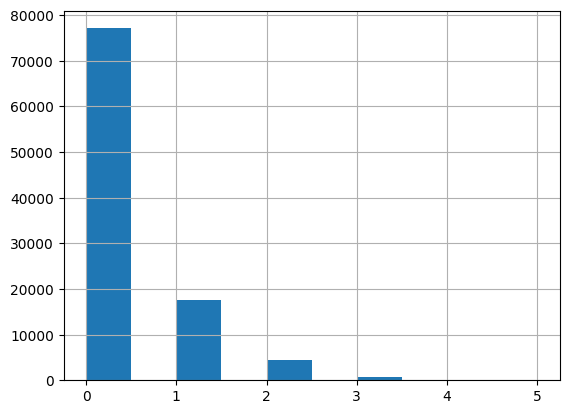

In [48]:
kk_data[dag_model.coef_.index].sum(axis=1).hist()

In [49]:
pd.crosstab(kk_data["Menstruationsschmerzen"],kk_data["endo"])

endo,False,True
Menstruationsschmerzen,,
False,86114,1493
True,11667,596


<Axes: xlabel='endo', ylabel='Urinieren'>

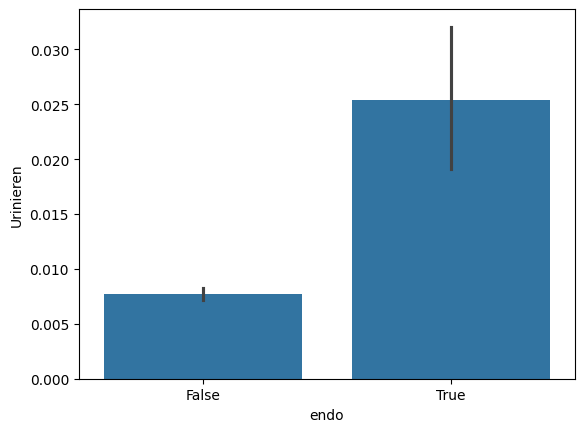

In [55]:
sns.barplot(data=kk_data,x="endo",y="Urinieren")

<Axes: xlabel='endo', ylabel='Verdauungsstörungen'>

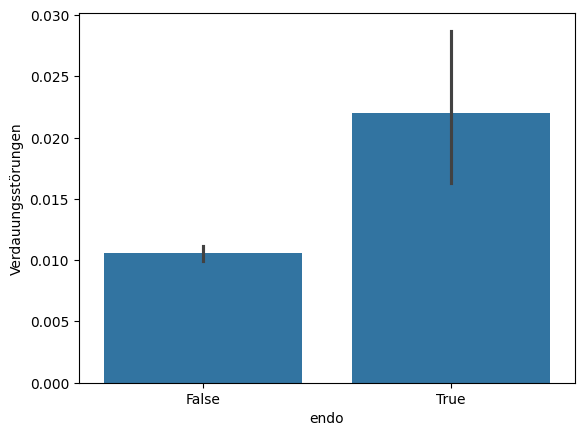

In [57]:
sns.barplot(data=kk_data,x="endo",y="Verdauungsstörungen")

<Axes: xlabel='endo', ylabel='Durchfall'>

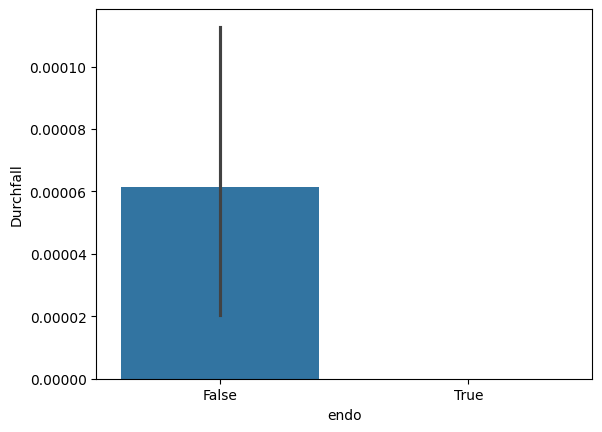

In [59]:
sns.barplot(data=kk_data,x="endo",y="Durchfall")

<Axes: xlabel='endo', ylabel='Bauchschmerzen'>

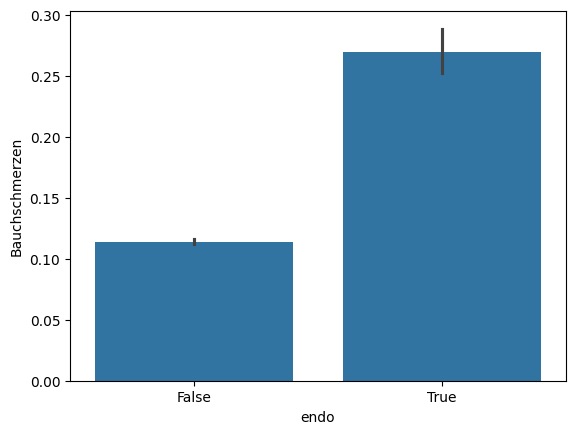

In [60]:
sns.barplot(data=kk_data,x="endo",y="Bauchschmerzen")

<Axes: xlabel='endo', ylabel='Menstruationsschmerzen'>

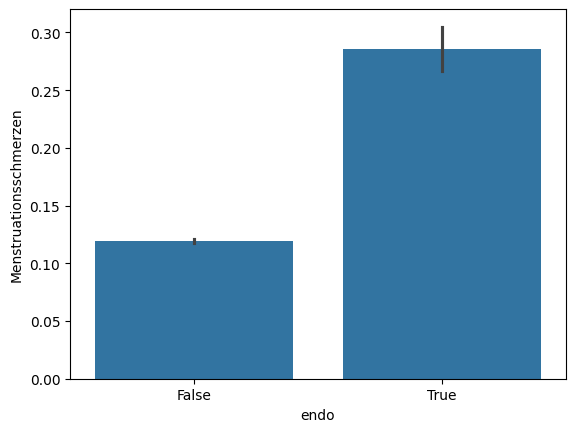

In [61]:
sns.barplot(data=kk_data,x="endo",y="Menstruationsschmerzen")

<Axes: xlabel='endo', ylabel='Dyspareunie'>

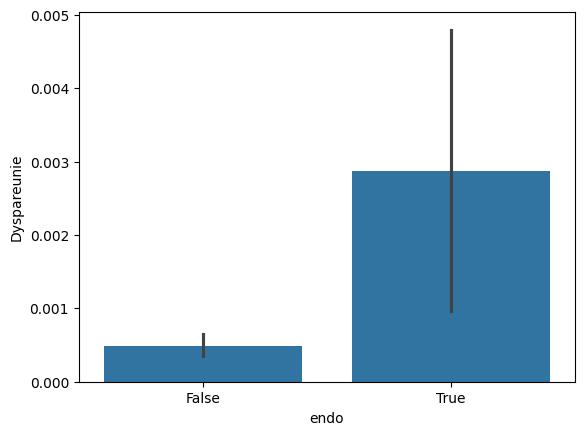

In [62]:
sns.barplot(data=kk_data,x="endo",y="Dyspareunie")

<Axes: xlabel='endo', ylabel='Blutung'>

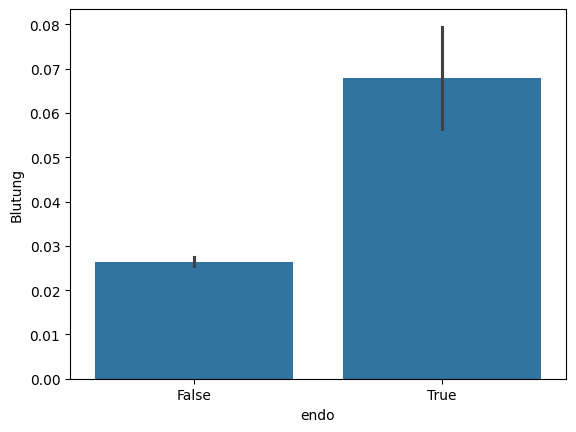

In [63]:
sns.barplot(data=kk_data,x="endo",y="Blutung")

<Axes: xlabel='endo', ylabel='Verstopfung'>

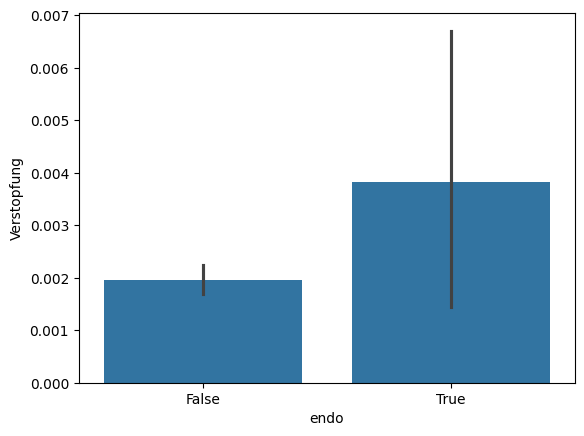

In [64]:
sns.barplot(data=kk_data,x="endo",y="Verstopfung")

In [65]:
pd.crosstab(kk_data["Menstruationsschmerzen"],kk_data["endo"])

endo,False,True
Menstruationsschmerzen,,
False,86114,1493
True,11667,596


## Which codes have "Z" (asymptomatic)?

In [68]:
z_codes = n80_df[n80_df["Diag_Sicherheit"]=="Z"]["code"].unique()

In [69]:
all_codes_list = pd.read_pickle("all_codes_list.pkl")

In [70]:
len(z_codes), len([z for z in z_codes if z in all_codes_list])

(42, 41)

## Which predictors have only "V"?

In [72]:
v_pred_codes = n80_df[(n80_df["Diag_Sicherheit"]=="V") & (~n80_df["code"].astype(str).str.contains("N80"))]["code"].unique()

In [73]:
len(v_pred_codes), len([z for z in v_pred_codes if z in all_codes_list])

(43, 42)

## Detail level of codes

In [75]:
n80_df["code"].str.contains("\.").value_counts() # some codes are on the superior level, e.g. "N80" instead of "N80.4"

code
False    768142
True      67234
Name: count, dtype: int64

In [76]:
n80_df[n80_df["code"].astype(str).str.contains("\.")]["source"].value_counts(dropna=False) # where do detail level codes come from

source
stat_prim    48149
stat_sek     18502
stat_ops       583
Name: count, dtype: int64

In [77]:
n80_df[~n80_df["code"].astype(str).str.contains("\.")]["source"].value_counts(dropna=False) # where do superior level codes come from

source
amb            381814
999            248578
ebm             97030
stat_prim       30188
stat_sek         7070
amb_kh_diag      3077
amb_kh_ops        385
Name: count, dtype: int64

# Where do endometriosis diagnoses come from first?

In [78]:
n80s = n80_df[(n80_df["endo"]==1) & (n80_df["code"].str.contains("N80"))].copy()

In [79]:
n80_beginn = n80s.groupby("VersID")["Beginn"].min().reset_index()

In [89]:
n80_beginn.head()

,VersID,Beginn
0,3,2023-07
1,18,2023-06
2,112,2022-07
3,114,2022-06
4,121,2022-05


In [97]:
n80_source.head()

,VersID,Beginn,source,code
0,3,2023-07,stat_prim,N80.3
1,3,2023-07,stat_prim,N80.3
2,18,2023-06,stat_prim,N80.0
3,18,2023-06,stat_prim,N80.0
4,18,2023-06,stat_prim,N80.1


In [101]:
n80_source[n80_source["VersID"].duplicated()]

,VersID,Beginn,source,code
1,3,2023-07,stat_prim,N80.3
3,18,2023-06,stat_prim,N80.0
4,18,2023-06,stat_prim,N80.1
5,18,2023-06,stat_prim,N80.1
6,18,2023-06,stat_prim,N80.1
...,...,...,...,...
2875,99822,2023-08,stat_prim,N80.3
2876,99822,2023-08,stat_prim,N80.3
2878,99880,2023-03,stat_prim,N80.3
2879,99880,2023-03,stat_prim,N80.1


In [102]:
n80_source[n80_source["VersID"]==18]

,VersID,Beginn,source,code
2,18,2023-06,stat_prim,N80.0
3,18,2023-06,stat_prim,N80.0
4,18,2023-06,stat_prim,N80.1
5,18,2023-06,stat_prim,N80.1
6,18,2023-06,stat_prim,N80.1
7,18,2023-06,stat_prim,N80.0


In [93]:
n80_source.shape, n80_source["VersID"].nunique()

((2881, 4), 2089)

In [105]:
n80_source.drop_duplicates(subset=["VersID","Beginn","source"]).groupby("VersID")["source"].unique().value_counts()

source
[amb]                 1736
[stat_prim]            236
[amb_kh_diag]           47
[amb, stat_prim]         1
[amb, amb_kh_diag]       1
                      ... 
[amb, stat_prim]         1
[amb, stat_prim]         1
[amb, amb_kh_diag]       1
[amb, stat_prim]         1
[amb, amb_kh_diag]       1
Name: count, Length: 73, dtype: int64

In [87]:
n80_df.groupby("endo")["VersID"].nunique() / n80_df["VersID"].nunique() # incidence rate

endo
False    0.979083
True     0.020917
Name: VersID, dtype: float64

# How old are patients at first N80 diagnosis?

In [108]:
df_test = n80_df.copy()

In [110]:
df_test["Beginn"].replace("999",np.nan,inplace=True)

df_test["Beginn"] = pd.to_datetime(df_test["Beginn"])

In [111]:

df_test["Geburtsjahr"] = pd.to_datetime(df_test["Geburtsjahr"],format="%Y",yearfirst=True)

In [ ]:
df_test["AktuellesJahr"] = 2026
df_test["AktuellesJahr"] = pd.to_datetime(df_test["AktuellesJahr"])

In [116]:
ages = df_test.groupby("VersID").apply(return_current_age).reset_index()

KeyboardInterrupt: 

In [ ]:
ages

In [10]:
df_age = df_test[df_test["code"].astype(str).str.contains("N80")].groupby("VersID").apply(return_age_in_years).reset_index()

/tmp/ipykernel_8704/38880141.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_age = df_test[df_test["code"].astype(str).str.contains("N80")].groupby("VersID").apply(return_age_in_years).reset_index()


In [11]:
df_age.rename(columns={0:"age_at_first_endo_diag"},inplace=True)

In [11]:
df_test = pd.merge(df_test,df_age,on="VersID")

In [75]:
df_test[["VersID","Geburtsjahr","Beginn","code","endometriosis","age_at_first_endo_diag"]].head()

,VersID,Geburtsjahr,Beginn,code,endometriosis,age_at_first_endo_diag
0,45311,1996-01-01,2021-10-01,33044,1,27
1,45311,1996-01-01,2023-12-01,33044,1,27
2,45311,1996-01-01,2023-08-01,33044,1,27
3,45311,1996-01-01,2023-08-01,33044,1,27
4,45311,1996-01-01,2022-09-01,33044,1,27


<Axes: >

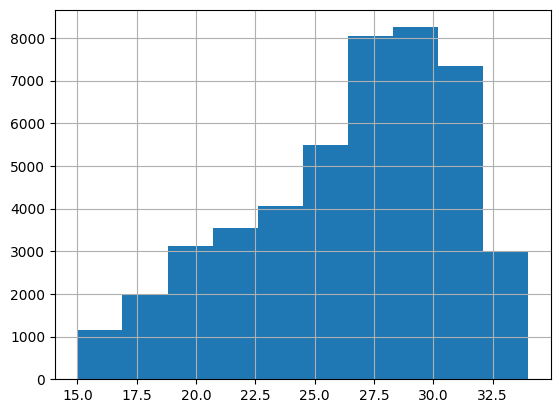

In [78]:
df_test["age_at_first_endo_diag"].hist()

In [85]:
df_test["age_at_first_endo_diag"].min(),df_test["age_at_first_endo_diag"].max()

(15, 34)

# Comorbidity Adenomyosis / Endometriosis

In [118]:
table = n80_df.groupby("VersID")["code"].apply(list)

In [121]:
adenomyosis_analysis(n80_df)

code
False    99437
True       433
Name: count, dtype: int64


N80 other,False,True
N80.0,,
False,99415,361
True,22,72


Prob(Endometriosis | Adenomyosis): 0.766, 
Prob(Adenomyosis | Endometriosis): 0.166, 
Prob(any of both): 0.005, 
Prob(only endometriosis): 0.004
Chi2: 12467.008683420521 p-value: 0.0


In [123]:
adenomyosis_analysis(n80_df[n80_df["endo"]==1])

code
False    1656
True      433
Name: count, dtype: int64


N80 other,False,True
N80.0,,
False,1649,361
True,7,72


Prob(Endometriosis | Adenomyosis): 0.911, 
Prob(Adenomyosis | Endometriosis): 0.166, 
Prob(any of both): 0.211, 
Prob(only endometriosis): 0.173
Chi2: 243.30104590830797 p-value: 7.498082341832172e-55


In [124]:
adenomyosis_analysis(n80_df[(n80_df["endo"]==1) & (n80_df["code"]!="N80")])

code
False    1649
True      433
Name: count, dtype: int64


N80 other,False,True
N80.0,,
False,1642,361
True,7,72


Prob(Endometriosis | Adenomyosis): 0.911, 
Prob(Adenomyosis | Endometriosis): 0.166, 
Prob(any of both): 0.211, 
Prob(only endometriosis): 0.173
Chi2: 242.24660850399016 p-value: 1.2730747348511377e-54


# Inzidenz

ca 0.021 

In [126]:
n80_df.groupby(["endo"])["VersID"].nunique()/n80_df["VersID"].nunique()

endo
False    0.979083
True     0.020917
Name: VersID, dtype: float64

In [127]:
has_n80 = n80_df[n80_df["code"].astype(str).str.contains("N80")]["VersID"].unique()